(what-is-this-block-groups-housing-worth-and-how-sure-are-we)=
# California housing values and prediction intervals

A house-value model is often published with an interval, and an interval that
is right on average can still be too narrow for some neighbourhoods and too
wide for others. This comparison predicts median house values for California
census block groups and evaluates 90% prediction intervals. A location-scale
boosted model lets both the mean and the spread of log values vary with the
covariates. The alternatives are a hedonic regression, a GAM, boosted trees
and a neural network, with constant-width intervals calibrated on the tuning
rows.

The data are the 1990 U.S. Census block-group records for California: Pace, R. K. and Barry, R. (1997), "Sparse spatial autoregressions", *Statistics & Probability Letters* 33(3), 291–297. Source: the StatLib archive's `cal_housing.tgz` as mirrored for scikit-learn, <https://ndownloader.figshare.com/files/5976036>. The file `california_housing_1990.csv` is the archive's `cal_housing.data` with column names added and the integer columns written as integers; no row is dropped or altered.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the predictive distribution of a block group's log median house value |
| **Observed response** | `median_house_value`, 1990 dollars, top-coded at \$500,001 (965 of 20,640 block groups) |
| **Estimand** | held-out error of the predicted median; log score and continuous ranked probability score (CRPS) of the predictive distribution; coverage of its 90% band |
| **Units** | log dollars and thousands of 1990 dollars; log score in nats (natural-log units) per block group, lower is better; CRPS in log dollars, lower is better |
| **Sampling unit** | each row is one census block group (20,640 rows); the response is that block group's median, not a sale |
| **Dependence** | neighbouring block groups are spatially correlated, so rows are not independent. Block groups are grouped into 0.1° × 0.1° cells and whole cells go to train (60%), tune (20%) or test (20%): no test block group shares a cell with a training row |
| **Claim type** | predictive: held-out accuracy and calibration, not causal effects of income or location |
| **Scope** | one state, one census; the top-coded rows are scored with a censored likelihood and left out of point and interval metrics |
:::

In [1]:
import time
import warnings
from pathlib import Path

import altair as alt
import lightgbm as lgb
import numpy as np
import polars as pl
import statsmodels.api as sm
import xgboost as xgb
from catboost import CatBoostRegressor
from IPython.display import display
from pygam import LinearGAM, s as pg_s, te as pg_te
from scipy.stats import norm
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from scipy.spatial import cKDTree
import matplotlib
from matplotlib import pyplot as plt

import mboostrs as mb

path = Path("california_housing_1990.csv")
if not path.exists():
    path = Path("docs/book/case_studies/california_housing_1990.csv")
raw = pl.read_csv(path)
CAP = 500_001
frame = raw.with_columns(
    pl.col("longitude").alias("lon"),
    pl.col("latitude").alias("lat"),
    pl.col("median_house_value").cast(pl.Float64).alias("value"),
    pl.col("median_house_value").log().alias("log_value"),
    (pl.col("median_house_value") >= CAP).alias("capped"),
    (pl.col("median_house_value") < CAP).cast(pl.Int64).alias("observed"),
    pl.col("median_income").log().alias("log_income"),
    pl.col("housing_median_age").cast(pl.Float64).alias("age"),
    (pl.col("total_rooms") / pl.col("households")).log().alias("log_rooms"),
    (pl.col("total_bedrooms") / pl.col("total_rooms")).alias("bed_share"),
    (pl.col("population") / pl.col("households")).log().alias("log_occupancy"),
    pl.col("households").log().alias("log_households"),
    ((pl.col("longitude") / 0.1).floor().cast(pl.Int64) * 10_000
     + (pl.col("latitude") / 0.1).floor().cast(pl.Int64)).alias("cell"),
)
cells = frame.select(pl.col("cell").unique().sort())
cells = cells.with_columns(pl.Series("u", np.random.default_rng(1990).random(cells.height)))
frame = frame.join(cells, on="cell", maintain_order="left").with_columns(
    pl.when(pl.col("u") < 0.6).then(pl.lit("train"))
    .when(pl.col("u") < 0.8).then(pl.lit("tune")).otherwise(pl.lit("test")).alias("split"))
train, tune, test = (frame.filter(pl.col("split") == s) for s in ("train", "tune", "test"))
print(f"{cells.height} cells; train {train.height}, tune {tune.height}, test {test.height} block groups; "
      f"top-coded: train {train['capped'].sum()}, tune {tune['capped'].sum()}, test {test['capped'].sum()}")

1595 cells; train 12524, tune 4432, test 3684 block groups; top-coded: train 654, tune 188, test 123


In [2]:
FEATURES = ["lon", "lat", "log_income", "age", "log_rooms", "bed_share", "log_occupancy", "log_households"]
Z90 = norm.ppf(0.95)
LOG_CAP = np.log(CAP)


def X(data):
    return data.select(FEATURES).to_numpy()


y_tr, y_tu, y_te = (d["log_value"].to_numpy() for d in (train, tune, test))
cap_tu, cap_te = tune["capped"].to_numpy(), test["capped"].to_numpy()
value_te = test["value"].to_numpy()
income_q = test.select(pl.col("median_income").qcut(5, labels=[f"Q{i}" for i in range(1, 6)])).to_series()


def censored_log_score(y, capped, mu, sigma):
    """Mean negative log predictive density; a top-coded row scores its survival above the cap."""
    sigma = np.broadcast_to(sigma, np.shape(mu))
    return float(np.mean(np.where(capped, -norm.logsf(LOG_CAP, mu, sigma), -norm.logpdf(y, mu, sigma))))


def gaussian_crps(y, mu, sigma):
    z = (y - mu) / sigma
    return sigma * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))


def sigma_on_tune(mu_tune):
    """Constant predictive sd for a point model: RMS error on the uncensored tuning rows."""
    return float(np.sqrt(np.mean((y_tu - mu_tune)[~cap_tu] ** 2)))


rows, bands = [], {}


def add(method, kind, mu, sigma, seconds, note="", lo=None, hi=None, density=True):
    unc = ~cap_te
    sigma = np.broadcast_to(np.asarray(sigma, dtype=float), mu.shape)
    if lo is None:
        lo, hi = mu - Z90 * sigma, mu + Z90 * sigma
    inside = (y_te >= lo) & (y_te <= hi)
    by_q = pl.DataFrame({"q": income_q, "inside": inside})
    by_q = by_q.filter(pl.Series(unc)).group_by("q").agg(pl.col("inside").mean()).sort("q")
    err = (y_te - mu)[unc]
    rows.append({
        "method": method, "kind": kind,
        "rmse_log": float(np.sqrt(np.mean(err**2))), "mae_log": float(np.mean(np.abs(err))),
        "mae_kusd": float(np.mean(np.abs(np.exp(mu[unc]) - value_te[unc]))) / 1e3,
        "log_score": censored_log_score(y_te, cap_te, mu, sigma) if density else None,
        "crps": float(np.mean(gaussian_crps(y_te[unc], mu[unc], sigma[unc]))) if density else None,
        "cover90": float(inside[unc].mean()),
        "worst_q_gap": float(np.max(np.abs(by_q["inside"].to_numpy() - 0.9))),
        "width90_kusd": float(np.mean(np.exp(hi[unc]) - np.exp(lo[unc]))) / 1e3,
        "seconds": round(seconds, 1), "note": note,
    })
    bands[method] = by_q["inside"].to_numpy()

/var/folders/pr/mdlxf70n2rl6445yj_0b0wx40000gn/T/ipykernel_90917/774330220.py:13: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  income_q = test.select(pl.col("median_income").qcut(5, labels=[f"Q{i}" for i in range(1, 6)])).to_series()


Every model sees the same eight features: location, log median income, median age, log rooms per household, the bedroom share of rooms, log occupancy and log household count. Each is fitted on the training cells. The tuning cells pick its complexity (penalty, rounds or boosting steps) and, for a point model, the width of its band: the predictive sd is the root mean squared error on the uncensored tuning rows, and the 90% band is the prediction plus or minus 1.645 times that sd. This is a Gaussian band whose width is set on held-out rows. The test cells are scored once.

The log score is the negative log predictive density at the observed value; a top-coded row scores the negative log probability of exceeding the cap. The CRPS compares the whole predictive distribution with the observed value and rewards a distribution that is both centred and narrow. `worst_q_gap` is the largest distance of the 90% band's coverage from 0.90 across the five quintiles of median income: a band can be right on average and wrong for the poorest or the richest block groups.

## Parametric and GAM baselines

In [3]:
start = time.time()
X_ols = lambda d: sm.add_constant(X(d), has_constant="add")
ols = sm.OLS(y_tr, X_ols(train)).fit()
add("OLS hedonic", "point + tuned sd", ols.predict(X_ols(test)), sigma_on_tune(ols.predict(X_ols(tune))),
    time.time() - start, "linear in the 8 features")

start = time.time()
terms = pg_te(0, 1, n_splines=[15, 15]) + pg_s(2, n_splines=15)
for i in range(3, 8):
    terms += pg_s(i, n_splines=15)
grid = []
for lam in np.logspace(-4, 2, 7):
    g = LinearGAM(terms, lam=lam).fit(X(train), y_tr)
    grid.append((sigma_on_tune(g.predict(X(tune))), lam, g))
sd, lam, gam = min(grid, key=lambda t: t[0])
add("pygam LinearGAM", "point + tuned sd", gam.predict(X(test)), sd, time.time() - start,
    f"te(lon, lat) + 6 s(), lam {lam:g}")

## Tree ensembles and a neural network

LightGBM, XGBoost and CatBoost with squared error on the log value, rounds chosen by early stopping on the tuning cells. Three ways to give trees a spread of their own: a second LightGBM, with a gamma objective, fitted to the squared tuning-cell residuals; LightGBM quantile regression at 5% and 95% (a band only, no density); and CatBoost's native `RMSEWithUncertainty`, which fits a mean and a variance jointly. The network is scikit-learn's `MLPRegressor`, two hidden layers of 64, on standardized inputs, with its L2 weight chosen on the tuning cells.

In [4]:
params = dict(objective="regression", learning_rate=0.05, num_leaves=31, min_data_in_leaf=20, verbose=-1, seed=1)
start = time.time()
booster = lgb.train(params, lgb.Dataset(X(train), y_tr), 5000, valid_sets=[lgb.Dataset(X(tune), y_tu)],
                    callbacks=[lgb.early_stopping(200, verbose=False)])
mu_tune_lgb, mu_lgb = booster.predict(X(tune)), booster.predict(X(test))
lgb_seconds = time.time() - start
add("LightGBM", "point + tuned sd", mu_lgb, sigma_on_tune(mu_tune_lgb), lgb_seconds,
    f"{booster.best_iteration} rounds")

start = time.time()
resid2, keep = (y_tu - mu_tune_lgb) ** 2, ~cap_tu
vparams = dict(objective="gamma", learning_rate=0.02, num_leaves=7, min_data_in_leaf=50, verbose=-1, seed=1)
cv = lgb.cv(vparams, lgb.Dataset(X(tune)[keep], resid2[keep]), 2000, nfold=5, stratified=False, seed=1,
            callbacks=[lgb.early_stopping(100, verbose=False)])
n_var = len(next(iter(cv.values())))
var_booster = lgb.train(vparams, lgb.Dataset(X(tune)[keep], resid2[keep]), n_var)
add("LightGBM + variance booster", "two-stage mean + sd", mu_lgb, np.sqrt(var_booster.predict(X(test))),
    lgb_seconds + time.time() - start, f"gamma booster on tuning r², {n_var} rounds")

start = time.time()
quantiles = {}
for a in (0.05, 0.95):
    qb = lgb.train(dict(params, objective="quantile", alpha=a), lgb.Dataset(X(train), y_tr), 5000,
                   valid_sets=[lgb.Dataset(X(tune), y_tu)], callbacks=[lgb.early_stopping(200, verbose=False)])
    quantiles[a] = qb.predict(X(test))
add("LightGBM quantile 5/95", "band only", mu_lgb, sigma_on_tune(mu_tune_lgb), time.time() - start,
    "band from two quantile boosters", lo=quantiles[0.05], hi=quantiles[0.95], density=False)

start = time.time()
d_tr, d_tu = xgb.DMatrix(X(train), y_tr), xgb.DMatrix(X(tune), y_tu)
xb = xgb.train(dict(objective="reg:squarederror", eta=0.05, max_depth=6, subsample=0.8, tree_method="hist", seed=1),
               d_tr, 5000, evals=[(d_tu, "tune")], early_stopping_rounds=200, verbose_eval=False)
it = (0, xb.best_iteration + 1)
add("XGBoost", "point + tuned sd", xb.predict(xgb.DMatrix(X(test)), iteration_range=it),
    sigma_on_tune(xb.predict(d_tu, iteration_range=it)), time.time() - start, f"{it[1]} rounds")

start = time.time()
cat_args = dict(iterations=5000, learning_rate=0.05, depth=6, random_seed=1, verbose=0, od_type="Iter",
                od_wait=200, use_best_model=True, thread_count=4, allow_writing_files=False)
cat = CatBoostRegressor(loss_function="RMSE", **cat_args).fit(X(train), y_tr, eval_set=(X(tune), y_tu))
mu_cat = cat.predict(X(test))
add("CatBoost", "point + tuned sd", mu_cat, sigma_on_tune(cat.predict(X(tune))), time.time() - start,
    f"{cat.get_best_iteration() + 1} iterations")

start = time.time()
cat_u = CatBoostRegressor(loss_function="RMSEWithUncertainty", **cat_args).fit(X(train), y_tr, eval_set=(X(tune), y_tu))
mean_var = cat_u.predict(X(test))  # columns: mean, variance
add("CatBoost RMSEWithUncertainty", "native mean + variance", mean_var[:, 0], np.sqrt(mean_var[:, 1]),
    time.time() - start, f"{cat_u.get_best_iteration() + 1} iterations")

start = time.time()
scaler = StandardScaler().fit(X(train))
grid = []
for alpha in (1e-4, 1e-3, 1e-2):
    net = MLPRegressor(hidden_layer_sizes=(64, 64), alpha=alpha, max_iter=400, early_stopping=True,
                       n_iter_no_change=20, random_state=1).fit(scaler.transform(X(train)), y_tr)
    grid.append((sigma_on_tune(net.predict(scaler.transform(X(tune)))), alpha, net))
sd, alpha, net = min(grid, key=lambda t: t[0])
add("MLP 64x64 (sklearn)", "point + tuned sd", net.predict(scaler.transform(X(test))), sd, time.time() - start,
    f"alpha {alpha:g}")

## mboostrs

Four fits, all on the same smooth terms: a tensor-product spline surface `bspatial(lon, lat)` plus a P-spline in each of the six other features.

1. `gamboost` with a Gaussian loss: a mean model, with a band built like the point models' bands.
2. `gamboostLSS` with `GaussianLSS()` at its defaults: smooth mean *and* smooth log-scale, fixed step `nu=0.1`, no gradient stabilization. This is what a caller who copies the R example gets.
3. The same model with `boost_control(..., step="line_search")`, which sizes every update on the likelihood.
4. `LogNormalLSS` on `Surv(value, observed)`: the same location-scale model on the log value, but a top-coded block group enters as *right-censored at \$500,001* instead of as a sale at the cap. None of the other models treats the capped values this way.

Steps are chosen on the tuning cells by the censored log score (the LSS fits) or the RMSE (`gamboost`). `predict(newdata, mstop=k)` scores a step count without refitting.

In [5]:
smooths = ("bbs(log_income, df=4) + bbs(age, df=4) + bbs(log_rooms, df=4) + bbs(bed_share, df=4)"
           " + bbs(log_occupancy, df=4) + bbs(log_households, df=4)")
mean_rhs = "bspatial(lon, lat, knots=30, df=6) + " + smooths
scale_rhs = "bspatial(lon, lat, knots=12, df=6) + " + smooths
fit_notes = {}


def caught_messages(caught):
    return [str(w.message) for w in caught if "outside the range" not in str(w.message)]


start = time.time()
cap_gb = 20_000
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    gb = mb.gamboost("log_value ~ " + mean_rhs, train, family=mb.Gaussian(), control=mb.boost_control(cap_gb, 0.5))
gb_curve = [(k, sigma_on_tune(np.asarray(gb.predict(tune, mstop=k, extrapolation="clip"))))
            for k in range(2000, cap_gb + 1, 2000)]
k_gb, sd_gb = min(gb_curve, key=lambda c: c[1])
mu_gb = np.asarray(gb.predict(test, mstop=k_gb, extrapolation="clip"))
add("mboostrs gamboost Gaussian", "point + tuned sd", mu_gb, sd_gb, time.time() - start,
    f"mstop {k_gb}/{cap_gb}, nu 0.5")
fit_notes["gamboost"] = caught_messages(caught)
print("tuning RMSE by step:", [(k, round(r, 4)) for k, r in gb_curve])


def fit_lss(name, response, family, control, step_grid):
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model = mb.gamboostLSS({"mu": f"{response} ~ {mean_rhs}", "sigma": f"{response} ~ {scale_rhs}"},
                               train, family=family, control=control)
    fit_seconds = time.time() - start
    curve = []
    for k in step_grid:
        p = model.predict(tune, type="response", mstop=k, extrapolation="clip")
        curve.append((k, censored_log_score(y_tu, cap_tu, np.asarray(p["mu"]), np.asarray(p["sigma"]))))
    k = min(curve, key=lambda c: c[1])[0]
    p = model.predict(test, type="response", mstop=k, extrapolation="clip")
    risk = np.asarray(model.risk)
    add(name, "smooth mean + smooth sd", np.asarray(p["mu"]), np.asarray(p["sigma"]), time.time() - start,
        f"mstop {k}/{step_grid[-1]}, fit {fit_seconds:.0f}s")
    fit_notes[name] = caught_messages(caught)
    print(f"{name}: training risk rose on {int(np.sum(np.diff(risk) > 1e-9))} of {risk.size - 1} iterations; "
          f"tuning log score by step {[(kk, round(s, 4)) for kk, s in curve[:: max(1, len(curve) // 6)]]}")
    return model, k


lss_default, k_default = fit_lss("mboostrs GaussianLSS, defaults", "log_value", mb.GaussianLSS(),
                                 mb.boost_control(1500, 0.1), list(range(100, 1501, 100)))
lss_ls, k_ls = fit_lss("mboostrs GaussianLSS, line search", "log_value", mb.GaussianLSS(),
                       mb.boost_control(1500, 0.5, step="line_search"), list(range(100, 1501, 100)))
lss_cens, k_cens = fit_lss("mboostrs LogNormalLSS, censored", "Surv(value, observed)", mb.LogNormalLSS(),
                           mb.boost_control(1500, 0.5, step="line_search"), list(range(100, 1501, 100)))

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households), covariate log_households: 1 below 0.693147 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Those rows were clipped to the training range, so the effect is held flat outside it rather than continuing at the edge slope.
  x_data, by_data = self._apply_extrapolation_policy(


tuning RMSE by step: [(2000, 0.2613), (4000, 0.2583), (6000, 0.2565), (8000, 0.2554), (10000, 0.2546), (12000, 0.254), (14000, 0.2535), (16000, 0.2532), (18000, 0.2529), (20000, 0.2527)]


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamlss.py:5307: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households) [mu], covariate log_households: 1 below 0.693147 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Those rows were clipped to the training range, so the effect is held flat outside it rather than continuing at the edge slope.
  eta = self._eta(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamlss.py:5307: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households) [sigma], covar

mboostrs GaussianLSS, defaults: training risk rose on 719 of 1500 iterations; tuning log score by step [(100, 0.1794), (300, 0.1777), (500, 0.1773), (700, 0.1773), (900, 0.1768), (1100, 0.1765), (1300, 0.1762), (1500, 0.176)]


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamlss.py:5307: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households) [mu], covariate log_households: 1 below 0.693147 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Those rows were clipped to the training range, so the effect is held flat outside it rather than continuing at the edge slope.
  eta = self._eta(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamlss.py:5307: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households) [sigma], covar

mboostrs GaussianLSS, line search: training risk rose on 0 of 1500 iterations; tuning log score by step [(100, 0.0772), (300, 0.0474), (500, 0.0388), (700, 0.0342), (900, 0.0318), (1100, 0.0315), (1300, 0.0323), (1500, 0.0327)]


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamlss.py:5307: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households) [mu], covariate log_households: 1 below 0.693147 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Those rows were clipped to the training range, so the effect is held flat outside it rather than continuing at the edge slope.
  eta = self._eta(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamlss.py:5307: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households) [sigma], covar

mboostrs LogNormalLSS, censored: training risk rose on 0 of 1500 iterations; tuning log score by step [(100, 0.06), (300, 0.0309), (500, 0.0247), (700, 0.0207), (900, 0.0178), (1100, 0.0168), (1300, 0.0194), (1500, 0.0302)]


## The scores

In [6]:
summary = pl.DataFrame(rows)
with pl.Config(tbl_rows=20, tbl_cols=-1, fmt_str_lengths=40, tbl_width_chars=260, tbl_hide_dataframe_shape=True):
    display(summary.select(pl.exclude("kind")).with_columns(
        pl.col("rmse_log", "mae_log", "log_score", "crps", "cover90", "worst_q_gap").round(3),
        pl.col("mae_kusd", "width90_kusd").round(1)))

method,rmse_log,mae_log,mae_kusd,log_score,crps,cover90,worst_q_gap,width90_kusd,seconds,note
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""OLS hedonic""",0.344,0.253,42.2,0.42,0.184,0.91,0.083,202.3,0.0,"""linear in the 8 features"""
"""pygam LinearGAM""",0.269,0.19,34.0,0.192,0.141,0.914,0.062,156.2,2.2,"""te(lon, lat) + 6 s(), lam 0.01"""
"""LightGBM""",0.261,0.183,32.2,0.161,0.136,0.907,0.059,144.7,4.8,"""709 rounds"""
"""LightGBM + variance booster""",0.261,0.183,32.2,0.135,0.133,0.864,0.054,123.9,9.2,"""gamma booster on tuning r², 445 rounds"""
"""LightGBM quantile 5/95""",0.261,0.183,32.2,null,null,0.894,0.062,369.0,4.1,"""band from two quantile boosters"""
"""XGBoost""",0.261,0.184,32.3,0.165,0.136,0.901,0.07,143.3,1.6,"""451 rounds"""
"""CatBoost""",0.254,0.178,31.1,0.135,0.131,0.916,0.069,141.0,3.0,"""1511 iterations"""
"""CatBoost RMSEWithUncertainty""",0.291,0.215,37.1,0.236,0.154,0.866,0.044,136.6,0.8,"""251 iterations"""
"""MLP 64x64 (sklearn)""",0.285,0.202,35.6,0.225,0.149,0.917,0.081,164.6,9.9,"""alpha 0.01"""


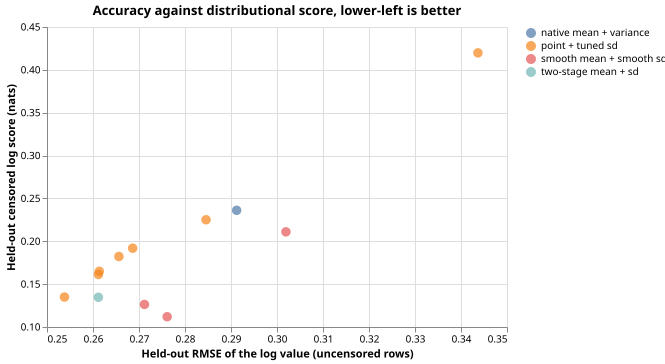

In [7]:
scored = summary.filter(pl.col("log_score").is_not_null())
alt.Chart(scored).mark_point(filled=True, size=90).encode(
    x=alt.X("rmse_log:Q", title="Held-out RMSE of the log value (uncensored rows)", scale=alt.Scale(zero=False)),
    y=alt.Y("log_score:Q", title="Held-out censored log score (nats)", scale=alt.Scale(zero=False)),
    color=alt.Color("kind:N", title=None),
    tooltip=["method", "rmse_log", "log_score", "cover90"],
).properties(width=460, height=300, title="Accuracy against distributional score, lower-left is better")

(where-the-bands-are-wrong)=
## Prediction-interval coverage

Coverage of the 90% band by income quintile, on the uncensored test rows. A constant-width band has the same width in log dollars everywhere; the location-scale fits let the width follow income and location.

In [8]:
show = ["CatBoost", "LightGBM + variance booster", "LightGBM quantile 5/95", "CatBoost RMSEWithUncertainty",
        "pygam LinearGAM", "mboostrs GaussianLSS, line search", "mboostrs LogNormalLSS, censored"]
coverage = pl.DataFrame({"income quintile": [f"Q{i}" for i in range(1, 6)]} | {m: bands[m] for m in show})
display(coverage.with_columns(pl.exclude("income quintile").round(3)))

income quintile,CatBoost,LightGBM + variance booster,LightGBM quantile 5/95,CatBoost RMSEWithUncertainty,pygam LinearGAM,"mboostrs GaussianLSS, line search","mboostrs LogNormalLSS, censored"
str,f64,f64,f64,f64,f64,f64,f64
"""Q1""",0.868,0.846,0.838,0.856,0.879,0.92,0.922
"""Q2""",0.896,0.876,0.872,0.857,0.894,0.913,0.916
"""Q3""",0.915,0.877,0.91,0.878,0.905,0.899,0.9
"""Q4""",0.938,0.856,0.924,0.862,0.934,0.891,0.895
"""Q5""",0.969,0.866,0.934,0.879,0.962,0.894,0.899


(what-the-location-scale-model-says)=
## Location and scale effects

The plots show the income terms in the mean and log standard deviation,
and the fitted standard deviation by test block-group location. In this fit, value rises with income; the spread *falls* with income through most of the range, so the poorest block groups need the widest bands in relative terms.

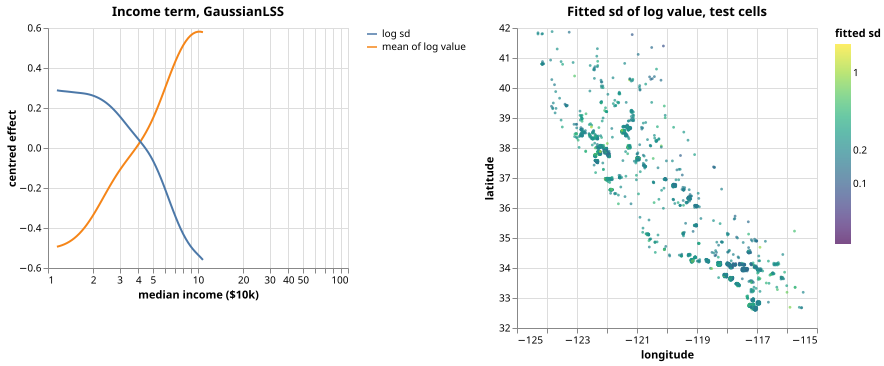

fitted sd of log value on test rows: 5% 0.134, median 0.216, 95% 0.479 (constant-band models use 0.253)


In [9]:
model, k = lss_ls, k_ls
grid = pl.DataFrame({"log_income": np.linspace(*np.quantile(train["log_income"].to_numpy(), [0.01, 0.99]), 60)})
grid = grid.with_columns([pl.lit(float(train[c].median())).alias(c) for c in FEATURES if c != "log_income"])
effects = []
for parameter in ("mu", "sigma"):
    _, values = model.partial_effects(parameter, newdata=grid, mstop=k)["log_income"]  # (x, effect)
    values = np.asarray(values, dtype=float)
    effects.append(pl.DataFrame({"median income ($10k)": np.exp(grid["log_income"].to_numpy()),
                                 "effect": values - values.mean(),
                                 "parameter": "mean of log value" if parameter == "mu" else "log sd"}))
effects = pl.concat(effects)
left = alt.Chart(effects).mark_line().encode(
    x=alt.X("median income ($10k):Q", scale=alt.Scale(type="log")), y=alt.Y("effect:Q", title="centred effect"),
    color=alt.Color("parameter:N", title=None)).properties(width=300, height=240, title="Income term, GaussianLSS")
p = model.predict(test, type="response", mstop=k, extrapolation="clip")
spread = test.select("lon", "lat").with_columns(pl.Series("sd", np.asarray(p["sigma"])))
right = alt.Chart(spread).mark_circle(size=8, opacity=0.7).encode(
    x=alt.X("lon:Q", scale=alt.Scale(zero=False), title="longitude"),
    y=alt.Y("lat:Q", scale=alt.Scale(zero=False), title="latitude"),
    color=alt.Color("sd:Q", scale=alt.Scale(scheme="viridis", type="log"), title="fitted sd"),
).properties(width=300, height=300, title="Fitted sd of log value, test cells")
display(left | right)
q = np.quantile(np.asarray(p["sigma"]), [0.05, 0.5, 0.95])
print(f"fitted sd of log value on test rows: 5% {q[0]:.3f}, median {q[1]:.3f}, 95% {q[2]:.3f} "
      f"(constant-band models use {sd_gb:.3f})")

(what-a-caller-hits-in-these-fits)=
## Fitting and prediction limitations

In [10]:
get = lambda m: summary.filter(pl.col("method") == m).row(0, named=True)
dflt, ls_r = get("mboostrs GaussianLSS, defaults"), get("mboostrs GaussianLSS, line search")
for name, messages in fit_notes.items():
    print(f"{name}: {len(messages)} warning(s)" + ("" if not messages else " -> " + messages[0][:160]))
risk = np.asarray(lss_default.risk)
rises = np.diff(risk) / np.maximum(np.abs(risk[:-1]), 1.0)
n_rises = int(np.sum(rises > 1e-9))
print(f"\nGaussianLSS defaults: risk rose on {n_rises} of {rises.size} iterations, "
      f"largest rise {rises.max():.1%} of the risk before it")
drift = gb.penalty_drift().filter(pl.col("learner").str.contains("bspatial"))
drift_bs, sel_bs = float(drift["boosted_df"][0]), int(drift["selections"][0])
display(drift)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    link = lss_ls.predict(test.head(3), mstop=k_ls, extrapolation="clip")
print("predict() with no type:", {name: np.round(np.asarray(v), 3).tolist() for name, v in link.items()},
      "|", [str(w.message)[:90] for w in caught][:1])
t0 = time.time()
gb.with_mstop(1000)
t1 = time.time()
gb.predict(tune, mstop=1000, extrapolation="clip")
print(f"gamboost with_mstop(1000): {t1 - t0:.1f}s; predict(newdata, mstop=1000): {time.time() - t1:.2f}s")

gamboost: 1 warning(s) -> boosting has undone much of the penalty of 5 learner(s): bbs(log_occupancy): 8.91 of 18 df after 244 selections (one step: 3.38); bbs(log_rooms): 9.92 of 21 df 
mboostrs GaussianLSS, defaults: 0 warning(s)
mboostrs GaussianLSS, line search: 0 warning(s)
mboostrs LogNormalLSS, censored: 0 warning(s)

GaussianLSS defaults: risk rose on 719 of 1500 iterations, largest rise 68.3% of the risk before it


learner,selections,single_step_df,boosted_df,unpenalized_df,drift_share
str,i64,f64,f64,f64,f64
"""bspatial(lon,lat)""",18161,5.13048,93.78295,413.0,0.217355


predict() with no type: {'mu': [12.789, 12.951, 12.841], 'sigma': [-1.622, -1.873, -1.555]} | ["predict() with default type='link' returns the mu: mean; sigma: log-scale for GaussianLSS;"]
gamboost with_mstop(1000): 0.0s; predict(newdata, mstop=1000): 0.02s


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households), covariate log_households: 1 below 0.693147 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Those rows were clipped to the training range, so the effect is held flat outside it rather than continuing at the edge slope.
  x_data, by_data = self._apply_extrapolation_policy(


- **GaussianLSS at its defaults oscillates without a warning.** With no gradient stabilization the location gradient is the residual divided by σ², so where the fitted spread is small a fixed `nu=0.1` step overshoots. The joint training risk rises on {eval}`f"{n_rises}"` of {eval}`f"{rises.size}"` cycles, the largest rise is {eval}`f"{rises.max():.0%}"` of the risk before it, and the tuning log score is still decreasing at the 1,500-step cap. The fit raises no warning. The remedies are `step="line_search"` or `stabilization="MAD"`. The defaults fit is worse on both scores: its RMSE ({eval}`f"{dflt['rmse_log']:.3f}"`) is worse than every model here except OLS, and its log score ({eval}`f"{dflt['log_score']:.3f}"`) is worse than a constant band around any of the tree models or the GAM.
- **`step="line_search"` removes the oscillation.** The same terms descend on every cycle and reach their best tuning score at {eval}`f"{k_ls}"` steps; the line search costs a little more per step ({eval}`f"{ls_r['seconds']:.0f}"` s against {eval}`f"{dflt['seconds']:.0f}"` s for the defaults, scoring included).
- **`predict()` on an LSS model returns the link scale by default** and warns that it does: the `sigma` printed is a log-sd. Pass `type="response"` for the standard deviation itself.
- **Changing the step count after the fit is fast.** On the 20,000-step `gamboost` path, `with_mstop(1000)` and `predict(newdata, mstop=1000)` each take under a second.
- **The spatial surface uses far more than its nominal `df=6`.** `penalty_drift()` reports, for each learner, the effective degrees of freedom of its accumulated boosted fit next to the df of a single step. It puts the boosted `bspatial` term at about {eval}`f"{drift_bs:.0f}"` effective df after {eval}`f"{sel_bs:,}"` selections. Each selection adds a shrunken penalized step, and the steps accumulate toward the unpenalized fit on the learner's basis, so the step count, not `df`, sets the term's flexibility. The `gamboost` tuning RMSE is still falling slowly at the 20,000-step cap ({eval}`f"{gb_curve[-2][1]:.4f}"` to {eval}`f"{gb_curve[-1][1]:.4f}"` over the last 2,000 steps), so a longer path would lower its RMSE a little; the curve has flattened.
- **Extrapolation is caught.** One block group falls below the training range of `log_households`; `predict` warns and `extrapolation="clip"` holds the edge flat.
- **The spatial learner is a tensor-product P-spline.** `bspatial(lon, lat)` builds a surface from products of B-splines in longitude and latitude. The radial-basis surface `brad(lon, lat)` is the alternative spatial learner; it is not compared here.

(do-mboostrs-trees-close-the-gap)=
## Joint-tree comparison

The Conclusions by dimension table compares tree libraries with smooth mboostrs fits. mboostrs
also has a tree learner, `btree`, and if the signal is tree-shaped a boosted
mboostrs tree should compete with the tree libraries. Three mboostrs tree
specifications are fitted on the same spatial-cell split: one joint tree over
all eight features with CART splits (`selection="sse"`, least squares), the
same tree with conditional-inference splits (`selection="ctree"`, a split
chosen by a permutation test of association), and one stump per feature.

The MLP serves as a smoothness check: a smooth function of all eight features
scores {eval}`f"{get('MLP 64x64 (sklearn)')['rmse_log']:.3f}"` log RMSE,
worse than the smooth additive model
({eval}`f"{get('mboostrs gamboost Gaussian')['rmse_log']:.3f}"`). What
CatBoost captures beyond the smooth fits is therefore not smooth in the eight
features, which is consistent with sharp spatial structure (coastlines,
neighbourhood boundaries) that axis-aligned splits can isolate and smooth
surfaces average over.

In [11]:
# mboostrs trees on the same spatial-cell holdout
from mboostrs.learners import Btree

def tune_gb(formula, cap, nu, learners=None, grid=None):
    fit = mb.gamboost(formula, data=train, family=mb.Gaussian(),
                      control=mb.boost_control(cap, nu),
                      **({"learners": learners} if learners else {}))
    grid = grid or list(range(200, cap + 1, 200))
    curve = [(k, sigma_on_tune(np.asarray(fit.predict(tune, mstop=k, extrapolation="clip")))) for k in grid]
    k = min(curve, key=lambda c: c[1])[0]
    return fit, k

# (a) blackboost-style: one joint tree over all 8 features, CART splits
start = time.time()
fit_sse, k_sse = tune_gb("log_value ~ .", 3000, 0.1, [Btree(FEATURES, maxdepth=6, minbucket=20, selection="sse")])
add("mboostrs btree(.) sse d6", "point + tuned sd",
    np.asarray(fit_sse.predict(test, mstop=k_sse, extrapolation="clip")),
    sigma_on_tune(np.asarray(fit_sse.predict(tune, mstop=k_sse, extrapolation="clip"))),
    time.time() - start, f"joint tree, mstop {k_sse}")

# (b) same, conditional-inference splits
start = time.time()
fit_ct, k_ct = tune_gb("log_value ~ .", 2000, 0.1, [Btree(FEATURES, maxdepth=6, minbucket=20, selection="ctree")])
add("mboostrs btree(.) ctree d6", "point + tuned sd",
    np.asarray(fit_ct.predict(test, mstop=k_ct, extrapolation="clip")),
    sigma_on_tune(np.asarray(fit_ct.predict(tune, mstop=k_ct, extrapolation="clip"))),
    time.time() - start, f"joint tree, mstop {k_ct}")

# (c) component-wise: one stump per feature
start = time.time()
fit_st, k_st = tune_gb("log_value ~ " + " + ".join(f"btree({f})" for f in FEATURES), 3000, 0.3)
add("mboostrs per-feature stumps", "point + tuned sd",
    np.asarray(fit_st.predict(test, mstop=k_st, extrapolation="clip")),
    sigma_on_tune(np.asarray(fit_st.predict(tune, mstop=k_st, extrapolation="clip"))),
    time.time() - start, f"mstop {k_st}")

summary = pl.DataFrame(rows)  # refresh: add() appends to rows
for m in ("mboostrs btree(.) sse d6", "mboostrs btree(.) ctree d6", "mboostrs per-feature stumps"):
    r = summary.filter(pl.col("method") == m).row(0, named=True)
    print(f"{m}: rmse_log {r['rmse_log']:.4f} ({r['note']})")

tree_sse = summary.filter(pl.col("method") == "mboostrs btree(.) sse d6").row(0, named=True)
tree_ct = summary.filter(pl.col("method") == "mboostrs btree(.) ctree d6").row(0, named=True)
tree_st = summary.filter(pl.col("method") == "mboostrs per-feature stumps").row(0, named=True)
tree_smooth = summary.filter(pl.col("method") == "mboostrs gamboost Gaussian").row(0, named=True)
tree_cb = summary.filter(pl.col("method") == "CatBoost").row(0, named=True)
del fit_sse, fit_ct, fit_st
import gc
gc.collect()

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: '.' leaves out 'split': it holds a single value in these rows, so no learner can fit an effect
  return function(*args, **kwargs)


mboostrs btree(.) sse d6: rmse_log 0.2663 (joint tree, mstop 200)
mboostrs btree(.) ctree d6: rmse_log 0.2692 (joint tree, mstop 600)
mboostrs per-feature stumps: rmse_log 0.2934 (mstop 1200)


70

(what-the-trees-say)=
### Joint-tree results

| mboostrs tree | rmse_log | vs CatBoost |
|---|---:|---|
| joint `Btree(.)`, `selection="sse"`, depth 6 | {eval}`f"{tree_sse['rmse_log']:.3f}"` | {eval}`f"{tree_sse['rmse_log'] - tree_cb['rmse_log']:+.3f}"` |
| joint `Btree(.)`, `selection="ctree"`, depth 6 | {eval}`f"{tree_ct['rmse_log']:.3f}"` | {eval}`f"{tree_ct['rmse_log'] - tree_cb['rmse_log']:+.3f}"` |
| per-feature stumps | {eval}`f"{tree_st['rmse_log']:.3f}"` | {eval}`f"{tree_st['rmse_log'] - tree_cb['rmse_log']:+.3f}"` |
| smooth `gamboost` (reference) | {eval}`f"{tree_smooth['rmse_log']:.3f}"` | {eval}`f"{tree_smooth['rmse_log'] - tree_cb['rmse_log']:+.3f}"` |

1. **mboostrs trees do not match CatBoost.** The joint CART tree scores
   {eval}`f"{tree_sse['rmse_log']:.3f}"`, against
   {eval}`f"{tree_smooth['rmse_log']:.3f}"` for the smooth fit and
   {eval}`f"{tree_cb['rmse_log']:.3f}"` for CatBoost. Per-feature stumps,
   which cannot represent interactions, score worst.
2. **Split criterion.** At the same depth, `selection="sse"` (CART, the
   `Btree` default) has a log RMSE
   {eval}`f"{tree_ct['rmse_log'] - tree_sse['rmse_log']:.3f}"` lower than
   `"ctree"`. The conditional-inference association test is conservative at
   the first split when the effect is not monotone, as the `Btree` docstring
   states, and sharp spatial boundaries are such a case.
3. **Specification search.** `autospec`, the library's automatic
   specification search, offers a joint tree only for the strongest pair
   found by its interaction screen: a two-column
   `btree(a, b, maxdepth=3, selection=sse)` that it adopts when held-out risk
   improves. A joint tree on all eight features at depth 6, as fitted here,
   is specified through `learners=[Btree(names, ...)]`.

The joint tree consists of {eval}`f"{k_sse}"` trees of depth up to 6, so its
fitted rules cannot be read one by one; the smooth fit is read through its
partial effects and its spatial surface. The censored `LogNormalLSS` fit
provides what none of the tree specifications here provides: a predictive
density that treats capped values as right-censored.

(very-close-still-interpretable-inside-a-60-second-budget)=
## Spatial models within 60 seconds

The reference smooth uses `df=6` for the spatial surface, chosen by hand, and
its tuning RMSE is still falling at the end of its path. This section asks how
close a readable smooth model comes to CatBoost when fitting and tuning
together must finish within 60 seconds, about
{eval}`f"{60 / tree_cb['seconds']:.0f}"` times CatBoost's measured
{eval}`f"{tree_cb['seconds']:.1f}"` s. Two changes are compared: a more
flexible spatial surface (`df=12`, with fewer knots, a larger step length
`nu` or more steps) and one depth-3 regression tree fitted to the training
residuals of the smooth fit. All use the same spatial split.

In [12]:
# Where does the time go? One bspatial smooth against the six bbs smooths
# alone, cost per boosting iteration. The spatial design (30 knots) and its
# penalty are fixed across iterations.
BUDGET_S = 60  # fit-and-tuning budget in seconds

def ms_per_iter(rhs, cap=2000, nu=0.5):
    t0 = time.time()
    f = mb.gamboost("log_value ~ " + rhs, train, family=mb.Gaussian(),
                    control=mb.boost_control(cap, nu))
    dt = time.time() - t0
    del f
    return dt / cap * 1000

ms_sp12 = ms_per_iter("bspatial(lon, lat, knots=30, df=12) + " + smooths)
ms_sp6 = ms_per_iter("bspatial(lon, lat, knots=30, df=6) + " + smooths)
ms_plain = ms_per_iter(smooths)
print(f"ms/iteration: bspatial df=12: {ms_sp12:.2f} | df=6: {ms_sp6:.2f} | six bbs, no spatial: {ms_plain:.2f}")

ms/iteration: bspatial df=12: 1.55 | df=6: 1.55 | six bbs, no spatial: 0.01


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 4 learner(s): bbs(log_occupancy): 9.72 of 18 df after 421 selections (one step: 3.38); bbs(log_rooms): 10.7 of 21 df after 443 selections (one step: 3.32); bbs(log_households): 10.7 of 23 df after 461 selections (one step: 3.34); bbs(bed_share): 8.82 of 18 df after 269 selections (one step: 3.34). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide

In [13]:
# Five smooth configurations against the budget: the largest step the API
# allows (nu=1.0), fewer knots, fewer iterations, and df=12 at nu=0.5 with
# 30k steps. Each is tuned on the tune cells and scored on the test cells
# like every other row; the seconds column records fit plus tuning time.
# Fits are freed after scoring and only the selected one is refitted, so
# peak memory is one fit.
import gc
fast_specs = [
    ("mboostrs smooth df=12, nu=1.0, 12k steps", "bspatial(lon, lat, knots=30, df=12) + " + smooths, 1.0, 12000, 2000),
    ("mboostrs smooth df=12, nu=1.0, 4k steps", "bspatial(lon, lat, knots=30, df=12) + " + smooths, 1.0, 4000, 1000),
    ("mboostrs smooth df=12, knots=15", "bspatial(lon, lat, knots=15, df=12) + " + smooths, 0.5, 6000, 1000),
    ("mboostrs smooth df=6, nu=1.0", "bspatial(lon, lat, knots=30, df=6) + " + smooths, 1.0, 4000, 1000),
    ("mboostrs smooth df=12, nu=0.5, 30k steps", "bspatial(lon, lat, knots=30, df=12) + " + smooths, 0.5, 30000, 3000),
]
fast_names = []
best_rmse, win = float("inf"), None
for name, rhs, nu, cap, step in fast_specs:
    t0 = time.time()
    f = mb.gamboost("log_value ~ " + rhs, train, family=mb.Gaussian(),
                    control=mb.boost_control(cap, nu))
    grid = list(range(step, cap + 1, step))
    curve = [(k, sigma_on_tune(np.asarray(f.predict(tune, mstop=k, extrapolation="clip")))) for k in grid]
    k = min(curve, key=lambda c: c[1])[0]
    mu = np.asarray(f.predict(test, mstop=k, extrapolation="clip"))
    secs = time.time() - t0
    sd = sigma_on_tune(np.asarray(f.predict(tune, mstop=k, extrapolation="clip")))
    r = float(np.sqrt(np.mean(((y_te - mu)[~cap_te]) ** 2)))
    add(name, "point + tuned sd", mu, sd, secs, f"mstop {k}/{cap}, nu {nu}")
    fast_names.append(name)
    print(f"{name}: k={k} rmse_log={r:.4f} seconds={secs:.1f}", flush=True)
    if secs <= BUDGET_S and r < best_rmse:
        best_rmse, win = r, (name, rhs, nu, cap, k)
    del f
    gc.collect()

summary = pl.DataFrame(rows)  # refresh: add() appends to rows
knots15_r = summary.filter(pl.col("method") == "mboostrs smooth df=12, knots=15").row(0, named=True)
# Re-fit only the winner: peak memory is one fit, not five.
feas_smooth_name, _rhs, _nu, _cap, feas_k = win
t0 = time.time()
feas_fit = mb.gamboost("log_value ~ " + _rhs, train, family=mb.Gaussian(),
                       control=mb.boost_control(_cap, _nu))
feas_secs = time.time() - t0
print("feasible smooth:", feas_smooth_name, f"re-fit in {feas_secs:.1f}s (tuned k={feas_k})")
gc.collect()

mboostrs smooth df=12, nu=1.0, 12k steps: k=12000 rmse_log=0.2596 seconds=4.4


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 6 learner(s): bbs(log_occupancy): 9.72 of 18 df after 209 selections (one step: 3.38); bbs(log_rooms): 10.8 of 21 df after 238 selections (one step: 3.32); bspatial(lon,lat): 182 of 442 df after 10705 selections (one step: 9.18); bbs(bed_share): 9.06 of 18 df after 157 selections (one step: 3.34); bbs(age): 11.3 of 24 df after 378 selections (one step: 3.39); bbs(log_households): 10.6 of 23 df after 212 selections (one step: 3.34). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this

mboostrs smooth df=12, nu=1.0, 4k steps: k=4000 rmse_log=0.2633 seconds=3.3


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): bbs(log_rooms): 9.23 of 21 df after 88 selections (one step: 3.32). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


mboostrs smooth df=12, knots=15: k=6000 rmse_log=0.2673 seconds=0.4


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 4 learner(s): bspatial(lon,lat): 84 of 187 df after 4679 selections (one step: 9.3); bbs(log_rooms): 9.34 of 21 df after 188 selections (one step: 3.32); bbs(age): 10.3 of 24 df after 470 selections (one step: 3.39); bbs(log_occupancy): 8.3 of 18 df after 162 selections (one step: 3.38). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-t

mboostrs smooth df=6, nu=1.0: k=4000 rmse_log=0.2664 seconds=3.4


mboostrs smooth df=12, nu=0.5, 30k steps: k=30000 rmse_log=0.2590 seconds=6.9


feasible smooth: mboostrs smooth df=12, nu=0.5, 30k steps re-fit in 6.6s (tuned k=30000)


30

In [14]:
# The selected model: the best smooth within the budget plus one depth-3 tree
# on its training residuals. The tree fit takes under a second; the budget is
# spent on the smooth. min_samples_leaf=100 keeps at least 100 block groups
# in every leaf.
t0 = time.time()
feas_mu_tr = np.asarray(feas_fit.predict(train, mstop=feas_k, extrapolation="clip"))
feas_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=100, random_state=0)
feas_tree.fit(X(train), y_tr - feas_mu_tr)
feas_leaves = feas_tree.get_n_leaves()
feas_mu = np.asarray(feas_fit.predict(test, mstop=feas_k, extrapolation="clip"))
feas_sd = sigma_on_tune(np.asarray(feas_fit.predict(tune, mstop=feas_k, extrapolation="clip")))
add("mboostrs selected smooth + tree (<=60 s)", "point + tuned sd",
    feas_mu + feas_tree.predict(X(test)), feas_sd, feas_secs + time.time() - t0,
    f"{feas_smooth_name}; one depth-3 tree, {feas_leaves} leaves")
print(export_text(feas_tree, feature_names=FEATURES))
summary = pl.DataFrame(rows)
feas_r = summary.filter(pl.col("method") == "mboostrs selected smooth + tree (<=60 s)").row(0, named=True)
feas_gap = feas_r["rmse_log"] - tree_cb["rmse_log"]
print(f"selected model: rmse_log {feas_r['rmse_log']:.4f} | CatBoost {tree_cb['rmse_log']:.4f} "
      f"| gap {feas_gap:+.4f} | seconds {feas_r['seconds']:.1f} | {feas_leaves} leaves")

|--- lon <= -118.23
|   |--- lat <= 34.00
|   |   |--- lat <= 33.89
|   |   |   |--- value: [0.08]
|   |   |--- lat >  33.89
|   |   |   |--- value: [-0.14]
|   |--- lat >  34.00
|   |   |--- lat <= 34.16
|   |   |   |--- value: [0.06]
|   |   |--- lat >  34.16
|   |   |   |--- value: [-0.00]
|--- lon >  -118.23
|   |--- log_occupancy <= 0.63
|   |   |--- value: [-0.18]
|   |--- log_occupancy >  0.63
|   |   |--- lon <= -118.01
|   |   |   |--- value: [0.05]
|   |   |--- lon >  -118.01
|   |   |   |--- value: [-0.00]

selected model: rmse_log 0.2584 | CatBoost 0.2538 | gap +0.0046 | seconds 6.7 | 7 leaves


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(log_households), covariate log_households: 1 below 0.693147 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Those rows were clipped to the training range, so the effect is held flat outside it rather than continuing at the edge slope.
  x_data, by_data = self._apply_extrapolation_policy(


In [15]:
# Two coarser spatial terms, each added to the reference (df=6) smooth: a
# k-means region map (8 dummies on lon/lat) and a hand-coded coastal dummy.
from sklearn.cluster import KMeans

km8 = KMeans(n_clusters=8, n_init=10, random_state=7).fit(train.select(["lon", "lat"]).to_numpy())
reg_cols = [f"reg8_{j}" for j in range(8)]
def with_regions(d):
    lab = km8.predict(d.select(["lon", "lat"]).to_numpy())
    return d.with_columns([pl.Series(c, (lab == j).astype(float)) for j, c in enumerate(reg_cols)])

def fit_tune_grid(formula, tr, tu, cap):
    f = mb.gamboost("log_value ~ " + formula, tr, family=mb.Gaussian(),
                    control=mb.boost_control(cap, 0.5))
    grid = list(range(3000, cap + 1, 3000))
    k = min(grid, key=lambda kk: sigma_on_tune(np.asarray(f.predict(tu, mstop=kk, extrapolation="clip"))))
    return f, k

t0 = time.time()
tr_rg, tu_rg, te_rg = with_regions(train), with_regions(tune), with_regions(test)
fit_reg, k_reg = fit_tune_grid(mean_rhs + " + " + " + ".join(reg_cols), tr_rg, tu_rg, 15_000)
add("mboostrs smooth + 8 region dummies", "point + tuned sd",
    np.asarray(fit_reg.predict(te_rg, mstop=k_reg, extrapolation="clip")),
    sigma_on_tune(np.asarray(fit_reg.predict(tu_rg, mstop=k_reg, extrapolation="clip"))),
    time.time() - t0, f"mstop {k_reg}/15000")

coast_pts = np.array([[-117.25, 32.55], [-118.45, 33.75], [-119.70, 34.40], [-120.60, 34.60],
                      [-121.90, 36.60], [-122.50, 37.80], [-123.30, 38.95], [-124.10, 40.45],
                      [-124.35, 41.75]])
def with_coastal(d):
    xy = np.stack([d["lon"].to_numpy(), d["lat"].to_numpy()], 1)
    cd = np.sqrt(((xy[:, None, :] - coast_pts[None]) ** 2).sum(-1)).min(1)
    return d.with_columns(pl.Series("coastal", (cd < 0.25).astype(float)))

t0 = time.time()
tr_c, tu_c, te_c = with_coastal(train), with_coastal(tune), with_coastal(test)
fit_co, k_co = fit_tune_grid(mean_rhs + " + coastal", tr_c, tu_c, 15_000)
add("mboostrs smooth + coastal dummy", "point + tuned sd",
    np.asarray(fit_co.predict(te_c, mstop=k_co, extrapolation="clip")),
    sigma_on_tune(np.asarray(fit_co.predict(tu_c, mstop=k_co, extrapolation="clip"))),
    time.time() - t0, f"mstop {k_co}/15000")

summary = pl.DataFrame(rows)
gb_r = summary.filter(pl.col("method") == "mboostrs gamboost Gaussian").row(0, named=True)
mlp_r = summary.filter(pl.col("method") == "MLP 64x64 (sklearn)").row(0, named=True)
reg_r = summary.filter(pl.col("method") == "mboostrs smooth + 8 region dummies").row(0, named=True)
coast_r = summary.filter(pl.col("method") == "mboostrs smooth + coastal dummy").row(0, named=True)
print(f"region dummies: {reg_r['rmse_log']:.4f} | coastal dummy: {coast_r['rmse_log']:.4f} "
      f"| ref smooth: {gb_r['rmse_log']:.4f}")
del fit_reg, fit_co, tr_rg, tu_rg, te_rg, tr_c, tu_c, te_c
import gc
gc.collect()

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 4 learner(s): bbs(reg8_2): 2 of 2 df after 43 selections (one step: 2); bbs(log_rooms): 9.55 of 21 df after 214 selections (one step: 3.32); bbs(log_occupancy): 8.51 of 18 df after 186 selections (one step: 3.38); bbs(age): 10.5 of 24 df after 524 selections (one step: 3.39). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  retur

region dummies: 0.2654 | coastal dummy: 0.2655 | ref smooth: 0.2656


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 3 learner(s): bbs(log_occupancy): 8.48 of 18 df after 183 selections (one step: 3.38); bbs(log_rooms): 9.47 of 21 df after 204 selections (one step: 3.32); bbs(age): 10.5 of 24 df after 507 selections (one step: 3.39). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


30

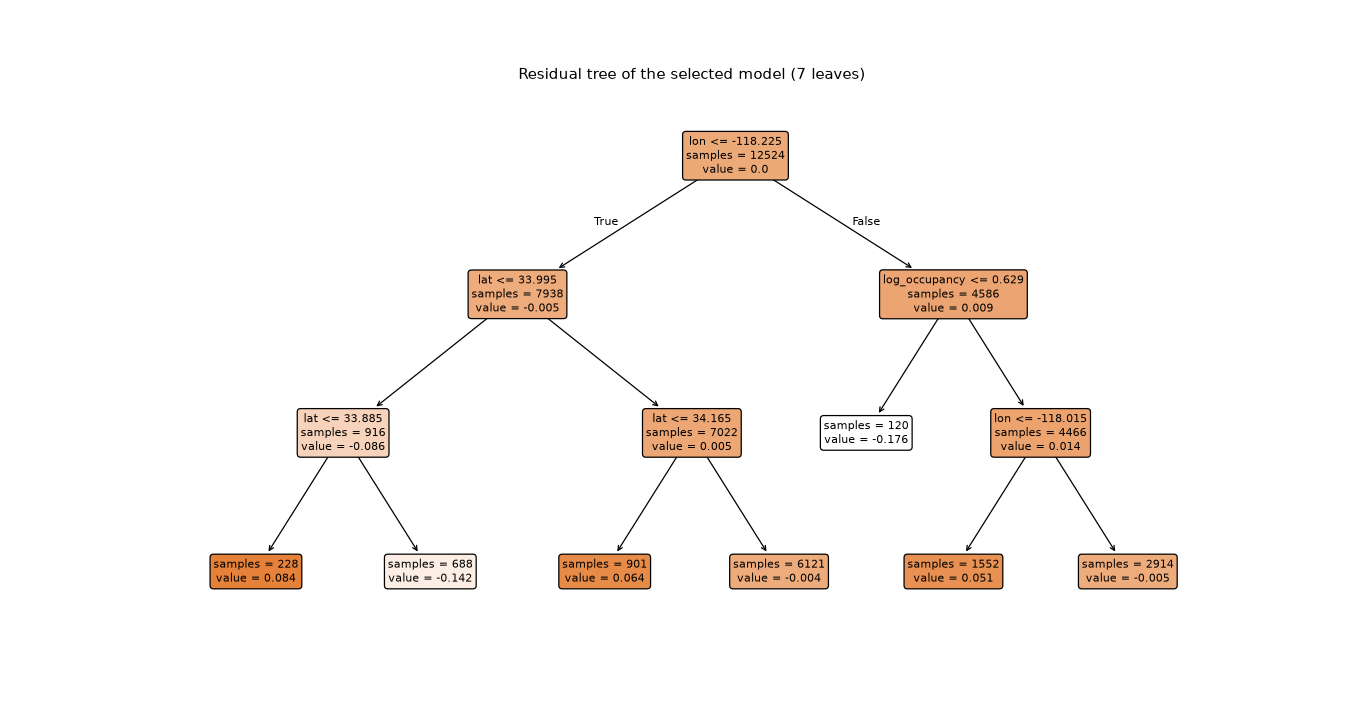

In [16]:
# The selected model's residual tree: log-point corrections to the smooth
# fit. Positive leaves are block groups the smooth underprices, negative
# leaves block groups it overprices.
import io
from IPython.display import Image

def show_png(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=90)
    plt.close(fig)
    display(Image(data=buf.getvalue()))

fig, ax = plt.subplots(figsize=(15, 8))
plot_tree(feas_tree, feature_names=FEATURES, filled=True, rounded=True, fontsize=9,
          ax=ax, impurity=False)
ax.set_title(f"Residual tree of the selected model ({feas_leaves} leaves)")
show_png(fig)

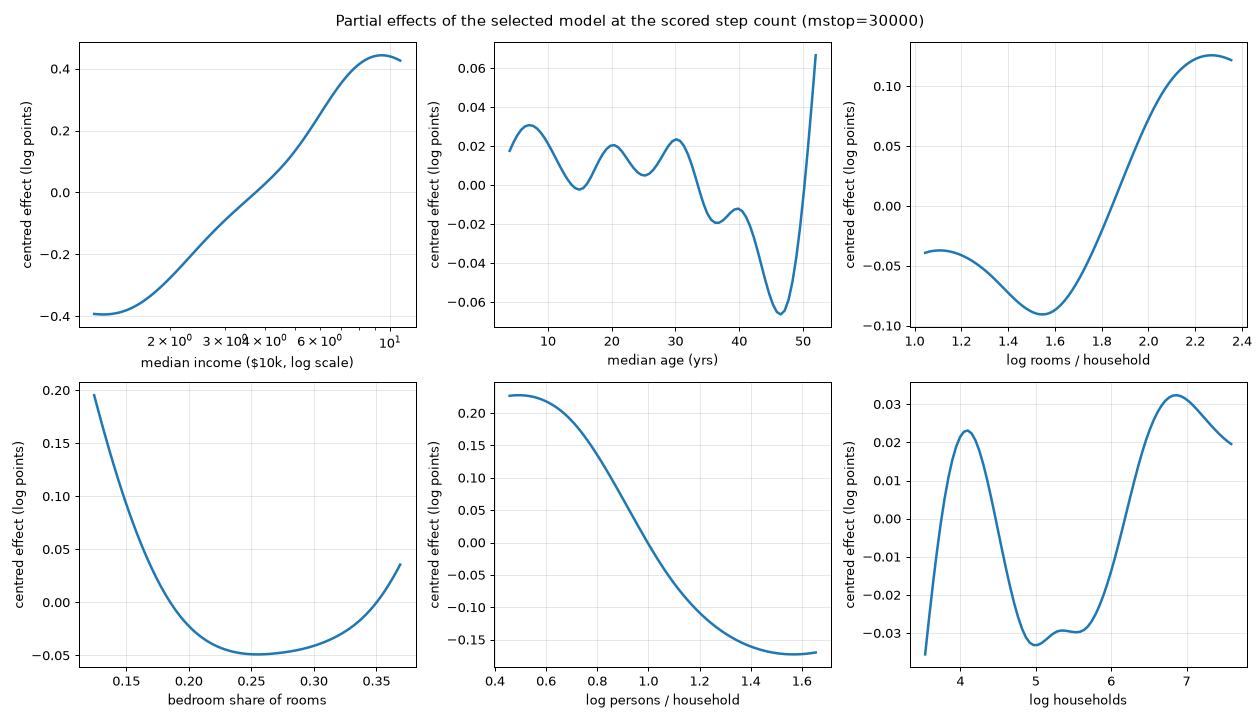

In [17]:
# Partial effects read off the SCORED model (mstop=feas_k): vary one feature
# over its central 98% range, hold the rest at train medians, predict. For an
# additive model this is the term's contribution, centred.
meds = {c: float(train[c].median()) for c in FEATURES}
plot_terms = ["log_income", "age", "log_rooms", "bed_share", "log_occupancy", "log_households"]
xlabels = {"log_income": "median income ($10k, log scale)", "age": "median age (yrs)",
           "log_rooms": "log rooms / household", "bed_share": "bedroom share of rooms",
           "log_occupancy": "log persons / household", "log_households": "log households"}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for axi, term in zip(axes.ravel(), plot_terms):
    xs = np.linspace(*np.quantile(train[term].to_numpy(), [0.01, 0.99]), 80)
    g = pl.DataFrame({term: xs, **{c: meds[c] for c in FEATURES if c != term}})
    eff = np.asarray(feas_fit.predict(g, mstop=feas_k, extrapolation="clip"), dtype=float)
    if term == "log_income":
        axi.set_xscale("log")
        axi.plot(np.exp(xs), eff - eff.mean(), lw=2)  # median_income is in $10k
    else:
        axi.plot(xs, eff - eff.mean(), lw=2)
    axi.set_xlabel(xlabels[term])
    axi.set_ylabel("centred effect (log points)")
    axi.grid(alpha=0.3)
fig.suptitle(f"Partial effects of the selected model at the scored step count (mstop={feas_k})")
fig.tight_layout()
show_png(fig)

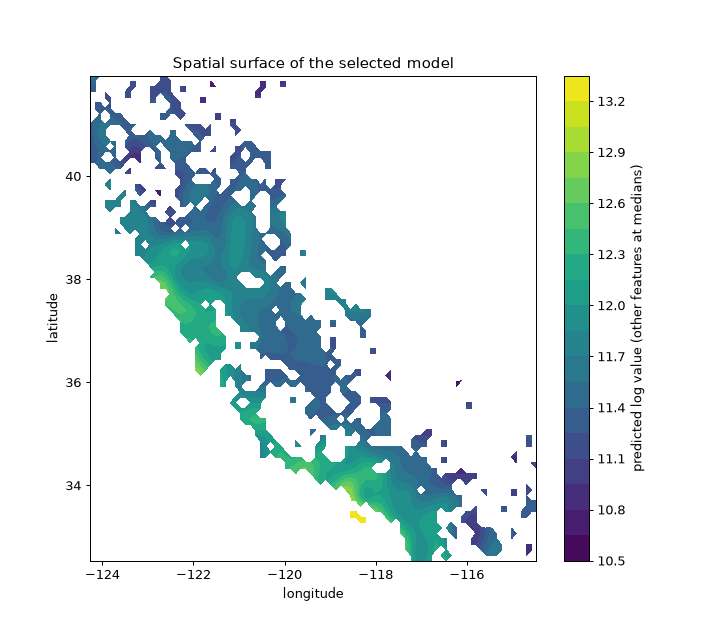

In [18]:
# The spatial surface: predict on a lon/lat grid with the other features at
# their medians, masked to the neighbourhood of the training data so the ocean
# and the desert stay blank instead of showing clipped-spline extrapolation.
lon_tr, lat_tr = train["lon"].to_numpy(), train["lat"].to_numpy()
glo = np.linspace(lon_tr.min(), lon_tr.max(), 90)
gla = np.linspace(lat_tr.min(), lat_tr.max(), 90)
LO, LA = np.meshgrid(glo, gla)
gsp = pl.DataFrame({"lon": LO.ravel(), "lat": LA.ravel(),
                    **{c: meds[c] for c in FEATURES if c not in ("lon", "lat")}})
surf = np.asarray(feas_fit.predict(gsp, mstop=feas_k, extrapolation="clip"), dtype=float).reshape(LO.shape)
near = cKDTree(np.column_stack([lon_tr, lat_tr])).query(
    np.column_stack([LO.ravel(), LA.ravel()]), k=1)[0]
surf = np.where(near.reshape(LO.shape) < 0.12, surf, np.nan)
fig, axi = plt.subplots(figsize=(8, 7))
cf = axi.contourf(LO, LA, surf, levels=24, cmap="viridis")
fig.colorbar(cf, ax=axi, label="predicted log value (other features at medians)")
axi.set_xlabel("longitude")
axi.set_ylabel("latitude")
axi.set_title("Spatial surface of the selected model")
show_png(fig)

(reading-the-champion)=
### Selected-model effects

The fitted effects describe associations among block-group characteristics
and housing values in this census. The plots and residual tree show the
following patterns:

1. **Coastal and inland values.** The spatial surface is near
   13.0 log points on the coastal strip (Bay Area, Los Angeles basin, San
   Diego) and near 11.5 a short distance inland: the Central Valley and inland
   Southern California are roughly a factor of four cheaper at the same
   values of the other features. The value changes over short distances near
   the coast, which is the structure that splits isolate and that the MLP, a
   smooth function of the features, does not capture (log RMSE
   {eval}`f"{mlp_r['rmse_log']:.3f}"`).

2. **Residual tree, west of downtown Los Angeles.** The first split is at
   longitude −118.23. West of it, three latitude splits mark bands of the Los
   Angeles basin: south of 33.89° the correction is +0.08; between 33.89° and
   34.00° it is −0.14, so the smooth surface overprices these block groups by
   about 13%; between 34.00° and 34.16° (central and west Los Angeles) it is
   +0.06; north of 34.16°, which covers the rest of the coast and Northern
   California, it is zero. These are boundaries that the smooth surface does
   not reproduce.

3. **Residual tree, east of downtown Los Angeles.** Block groups with log
   occupancy at most 0.63 (fewer than about 1.9 persons per household; 120
   training block groups) receive the largest correction, −0.18, so the
   smooth fit overpredicts them by about 16%. The global occupancy curve falls
   with occupancy, so low occupancy predicts a higher value; the tree finds
   that this does not hold for these block groups. Among the remaining
   block groups, those between −118.23 and −118.01 (eastern Los Angeles
   County) receive +0.05 and those further east zero.

4. **Income, age and household count.** The income effect rises 0.8 log points from the poorest to the
   richest block groups and flattens at the top. Median age
   and the household count vary within about ±0.03 to ±0.06, an order of magnitude less.
   These spans describe the size of each fitted contribution; they do not
   measure uncertainty or causal importance.

5. **Remaining log-RMSE difference: {eval}`f"{feas_gap:.3f}"`.** The selected model
   ({eval}`f"{feas_r['rmse_log']:.3f}"`, {eval}`f"{feas_r['seconds']:.0f}"` s)
   trails CatBoost ({eval}`f"{tree_cb['rmse_log']:.3f}"`,
   {eval}`f"{tree_cb['seconds']:.0f}"` s) by {eval}`f"{feas_gap:.3f}"`
   log-RMSE. The selected fit is read through six partial-effect plots, one spatial
   map and one {eval}`f"{feas_leaves}"`-leaf tree whose splits are all listed,
   against {eval}`f"{cat.get_best_iteration() + 1:,}"` CatBoost trees. The
   censored `LogNormalLSS` fit also supplies a predictive density for
   top-coded observations, which these tree specifications do not.

(how-the-specification-was-found-and-what-the-clock-says)=
### Specification comparisons and runtime

The reference spatial smooth uses `df=6`, chosen by hand. Its tuning curve is
still decreasing at the end of the path, so `df=12` on the same 30 knots is
compared. This increases the flexibility of each spatial update and keeps the
same covariates and partial-effect plots.

Two coarser spatial terms added to the reference smooth do not improve it:
eight k-means region dummies score {eval}`f"{reg_r['rmse_log']:.3f}"` and a
hand-coded coastal dummy {eval}`f"{coast_r['rmse_log']:.3f}"`, against
{eval}`f"{gb_r['rmse_log']:.3f}"` for the reference smooth. Coarse regions
cannot follow the coastline, and the smooth surface already represents it.
The residual tree is the smallest step beyond an additive model: one depth-3
tree on the training residuals, {eval}`f"{feas_leaves}"` leaves, each split
listed.

Runtime has two parts, the complete fit and its per-iteration cost:

(a) **Within the budget**, the best model is the selected model:
{eval}`f"{feas_r['rmse_log']:.3f}"` in {eval}`f"{feas_r['seconds']:.0f}"` s
({eval}`f"{feas_smooth_name}"`). The 15-knot spatial surface fits in
{eval}`f"{knots15_r['seconds']:.1f}"` s but scores
{eval}`f"{knots15_r['rmse_log']:.3f}"`; coarse knots cannot follow the
coastline.

(b) **Spatial-update cost.** One boosting iteration costs
{eval}`f"{ms_sp12:.1f}"` ms with the `df=12` `bspatial` term against
{eval}`f"{ms_plain:.2f}"` ms for the six `bbs` learners alone. The iteration
count is large because component-wise descent with `nu ≤ 1` converges
slowly: the selected specification uses {eval}`f"{feas_k:,}"` updates.

(findings-not-a-verdict)=
## Accuracy and runtime results

For point prediction, the reference smooth terms with a more flexible spatial
surface plus one
{eval}`f"{feas_leaves}"`-leaf residual tree reach {eval}`f"{feas_r['rmse_log']:.3f}"`
log-RMSE in {eval}`f"{feas_r['seconds']:.0f}"` s, within {eval}`f"{feas_gap:+.3f}"` of
CatBoost. Runtime is treated as a hard limit: a model that needs more than the
60 s budget is not counted as close to CatBoost.

In [19]:
get = lambda m: summary.filter(pl.col("method") == m).row(0, named=True)
cat_r, lgbv, cat_u_r = get("CatBoost"), get("LightGBM + variance booster"), get("CatBoost RMSEWithUncertainty")
ls_r, cens, dflt, gbr = (get("mboostrs GaussianLSS, line search"), get("mboostrs LogNormalLSS, censored"),
                         get("mboostrs GaussianLSS, defaults"), get("mboostrs gamboost Gaussian"))
gam_r, mlp, xg, lg, ols_r = (get("pygam LinearGAM"), get("MLP 64x64 (sklearn)"), get("XGBoost"), get("LightGBM"),
                             get("OLS hedonic"))
best_point = summary.sort("rmse_log").row(0, named=True)
best_density = scored.sort("log_score").row(0, named=True)
density_rows = scored.filter(pl.col("method").str.contains("LSS|variance|Uncertainty|CatBoost$"))
fairest = density_rows.sort("worst_q_gap").row(0, named=True)
verdict_text = (
    f"On the point value, tree ensembles win: {best_point['method']} has the lowest held-out RMSE "
    f"({best_point['rmse_log']:.3f} log, MAE ${best_point['mae_kusd']:.1f}k), against {gbr['rmse_log']:.3f} for "
    f"mboostrs' mean-only gamboost, {ls_r['rmse_log']:.3f} for the line-search GaussianLSS and "
    f"{cens['rmse_log']:.3f} for the censored LogNormalLSS. On the distribution the order reverses: the "
    f"location-scale fits score {ls_r['log_score']:.3f} (GaussianLSS) and {cens['log_score']:.3f} "
    f"(censored LogNormalLSS) nats against {cat_r['log_score']:.3f} for CatBoost with a tuned constant band and "
    f"{lgbv['log_score']:.3f} for LightGBM with a second variance booster. CRPS, which rewards accuracy and "
    f"sharpness together, is close at the top ({ls_r['crps']:.3f} GaussianLSS against {cat_r['crps']:.3f} "
    f"CatBoost), because CatBoost's better centre offsets its constant width. The bands differ most by "
    f"neighbourhood: CatBoost's constant band covers {bands['CatBoost'][0]:.1%} in the poorest income quintile "
    f"and {bands['CatBoost'][-1]:.1%} in the richest, the LSS band {bands['mboostrs GaussianLSS, line search'][0]:.1%} "
    f"and {bands['mboostrs GaussianLSS, line search'][-1]:.1%}. The trees' own spread models undercover overall "
    f"(variance booster {lgbv['cover90']:.1%}, CatBoost RMSEWithUncertainty {cat_u_r['cover90']:.1%}). "
    f"{fairest['method']} has the smallest worst-quintile gap ({fairest['worst_q_gap']:.3f}). GaussianLSS at its "
    f"defaults scores {dflt['log_score']:.3f} nats with an RMSE of {dflt['rmse_log']:.3f}, behind the GAM."
)
print(verdict_text)

On the point value, tree ensembles win: CatBoost has the lowest held-out RMSE (0.254 log, MAE $31.1k), against 0.266 for mboostrs' mean-only gamboost, 0.271 for the line-search GaussianLSS and 0.276 for the censored LogNormalLSS. On the distribution the order reverses: the location-scale fits score 0.126 (GaussianLSS) and 0.112 (censored LogNormalLSS) nats against 0.135 for CatBoost with a tuned constant band and 0.135 for LightGBM with a second variance booster. CRPS, which rewards accuracy and sharpness together, is close at the top (0.137 GaussianLSS against 0.131 CatBoost), because CatBoost's better centre offsets its constant width. The bands differ most by neighbourhood: CatBoost's constant band covers 86.8% in the poorest income quintile and 96.9% in the richest, the LSS band 92.0% and 89.4%. The trees' own spread models undercover overall (variance booster 86.4%, CatBoost RMSEWithUncertainty 86.6%). mboostrs GaussianLSS, line search has the smallest worst-quintile gap (0.020). 

## Conclusions by dimension

| Dimension | OLS hedonic | pygam GAM | LightGBM / XGBoost / CatBoost | MLP | mboostrs `gamboost` | mboostrs `gamboostLSS` (line search; censored LogNormal) |
|---|---|---|---|---|---|---|
| **Point accuracy (RMSE log / MAE)** | {eval}`f"{ols_r['rmse_log']:.3f} / ${ols_r['mae_kusd']:.0f}k"`, worst | {eval}`f"{gam_r['rmse_log']:.3f} / ${gam_r['mae_kusd']:.0f}k"` | **best**: CatBoost {eval}`f"{cat_r['rmse_log']:.3f} / ${cat_r['mae_kusd']:.0f}k"`; LightGBM {eval}`f"{lg['rmse_log']:.3f}"`, XGBoost {eval}`f"{xg['rmse_log']:.3f}"` | {eval}`f"{mlp['rmse_log']:.3f} / ${mlp['mae_kusd']:.0f}k"` | {eval}`f"{gbr['rmse_log']:.3f} / ${gbr['mae_kusd']:.0f}k"`, level with the GAM; the selected model under the 60 s budget reaches {eval}`f"{feas_r['rmse_log']:.3f}"` in {eval}`f"{feas_r['seconds']:.0f}"` s | {eval}`f"{ls_r['rmse_log']:.3f}; {cens['rmse_log']:.3f}"`, behind the trees |
| **Log score (censored, nats)** | {eval}`f"{ols_r['log_score']:.3f}"` | {eval}`f"{gam_r['log_score']:.3f}"` | constant band {eval}`f"{cat_r['log_score']:.3f}"` (CatBoost); variance booster {eval}`f"{lgbv['log_score']:.3f}"`; native variance {eval}`f"{cat_u_r['log_score']:.3f}"` | {eval}`f"{mlp['log_score']:.3f}"` | {eval}`f"{gbr['log_score']:.3f}"` | **best**: {eval}`f"{ls_r['log_score']:.3f}; {cens['log_score']:.3f}"` |
| **CRPS (log scale)** | {eval}`f"{ols_r['crps']:.3f}"` | {eval}`f"{gam_r['crps']:.3f}"` | **best**: CatBoost {eval}`f"{cat_r['crps']:.3f}"`; variance booster {eval}`f"{lgbv['crps']:.3f}"` | {eval}`f"{mlp['crps']:.3f}"` | {eval}`f"{gbr['crps']:.3f}"` | close: {eval}`f"{ls_r['crps']:.3f}; {cens['crps']:.3f}"` |
| **Calibration of the 90% band (overall; worst income-quintile gap)** | {eval}`f"{ols_r['cover90']:.2f}; {ols_r['worst_q_gap']:.2f}"` | {eval}`f"{gam_r['cover90']:.2f}; {gam_r['worst_q_gap']:.2f}"` | tuned constant band right on average, wrong by income (CatBoost {eval}`f"{cat_r['cover90']:.2f}; {cat_r['worst_q_gap']:.2f}"`); their own spread models undercover ({eval}`f"{lgbv['cover90']:.2f}"`, {eval}`f"{cat_u_r['cover90']:.2f}"`) | {eval}`f"{mlp['cover90']:.2f}; {mlp['worst_q_gap']:.2f}"` | {eval}`f"{gbr['cover90']:.2f}; {gbr['worst_q_gap']:.2f}"` | **best**: {eval}`f"{ls_r['cover90']:.2f}; {ls_r['worst_q_gap']:.2f}"` and {eval}`f"{cens['cover90']:.2f}; {cens['worst_q_gap']:.2f}"`; width follows income and place |
| **Interpretability** | signed coefficients, wrong shape | readable smooths and surface | SHAP only; no spread to read | none | additive terms, partial effects, spatial surface (the selected model adds one {eval}`f"{feas_leaves}"`-leaf tree) | the same for the mean **and** the spread; income effects on both are plotted in Location and scale effects |
| **Defaults and pitfalls** | none | one λ for every term, picked on a grid by hand | quantile band {eval}`f"${summary.filter(pl.col('method') == 'LightGBM quantile 5/95')['width90_kusd'][0]:.0f}k"` wide; variance booster and native variance undercover | needs standardized inputs; behind the GAM here | penalty drift on `bspatial` (step count, not `df`, sets its flexibility) | **GaussianLSS defaults oscillate without a warning**; `predict` returns the link scale unless `type="response"`; use `step="line_search"` |
| **Top-coding at \$500,001** | ignored | ignored | ignored | ignored | ignored | **handled** by `LogNormalLSS` on `Surv(value, observed)` |
| **Runtime (fit + tuning)** | {eval}`f"{ols_r['seconds']:.1f} s"` | {eval}`f"{gam_r['seconds']:.0f} s"` | {eval}`f"{xg['seconds']:.1f}–{cat_r['seconds']:.1f} s"` | {eval}`f"{mlp['seconds']:.0f} s"` | {eval}`f"{gbr['seconds']:.0f} s"` | {eval}`f"{ls_r['seconds']:.0f} s; {cens['seconds']:.0f} s"` |
| **Prefer it when** | a sign check | a quick smooth benchmark | only the point value is published | not on this data | a mean-only smooth, readable model | the band is published, should vary by place, or the response is capped |

**Reading the tradeoffs.** No single model is best on every dimension, and the choice depends on which dimension the decision needs. For the point value, CatBoost is the most accurate here (about {eval}`f"${gbr['mae_kusd'] - cat_r['mae_kusd']:.0f}k"` per block group better in MAE than the mboostrs mean-only `gamboost`, trained in seconds); the joint mboostrs tree ({eval}`f"{tree_sse['rmse_log']:.3f}"`) and the smooth `gamboost` ({eval}`f"{gbr['rmse_log']:.3f}"`) both trail it in log RMSE. For the band, the censored `LogNormalLSS` (line search) has the best log score, near-nominal coverage in every income quintile, a spread a reviewer can read term by term, and is the only model that treats the \$500,001 rows as "at least" rather than as sales at the cap; a constant-width band is right on average and wrong by neighbourhood. If one model must do both jobs, the line-search `GaussianLSS` gives up {eval}`f"{ls_r['rmse_log'] - cat_r['rmse_log']:.3f}"` in log RMSE for a band that is right where the constant band is not. `GaussianLSS` at its defaults is not a candidate: its path oscillates and its mean is worse than the GAM's. The LightGBM quantile band is the widest here and the `RMSEWithUncertainty` intervals undercover, so neither is recommended.

## Limitations and open problems

- One state and one census. The ranking of models can differ on other housing
  data, and the spatial-cell split measures transfer to nearby unseen cells,
  not to another region.
- Runtimes are wall-clock times on one machine and include tuning; the 60 s
  budget is relative to CatBoost's time on the same machine.
- `GaussianLSS` at its defaults oscillates on these data without a warning;
  use `step="line_search"` or `stabilization="MAD"`.
- Open question: whether the remaining gap between the joint mboostrs tree
  and CatBoost comes from the split criterion and tree-growth policy or from
  CatBoost's ordered boosting (its scheme for computing each row's gradient
  from models that were not fitted to that row).

## Reproduction

The cells prepare the data, fit the models and calculate every reported
score; no external result is loaded. Geographic cells, not individual rows,
are assigned to training, tuning and test sets with
`numpy.random.default_rng(1990)`. Model random states and other settings are
in the fitting cells. Data file: `california_housing_1990.csv` (sha256 of the
source archive `aaa5c9a6afe2225cc2aed2723682ae403280c4a3695a2ddda4ffb5d8215ea681`).